In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/input_model_potenc_predXfault7_A.csv")

print(df.shape)
display(df.head())

(8737, 20)


,timestamp,fault_d7,4700008966_kW,4700008966_power_hour,4408411600_kW,4408411600_power_hour,4608927500_kvar_hour,238045_ws_temp,279805_ws_vigor,279804_ws_level,279625_ws_temp,279623_ws_vigor,319235_ws_temp,279831_ws_temp,326417_ws_temp,326416_ws_vigor,temp_site1_anomaly_score,sfc_temp_site1_anomaly_score,gw_lvl_site2_anomaly_score,gw_temp_site2_anomaly_score
0,31-12-2021 23:00,0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01-01-2022 0:00,0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.34,7.63,9.48,38.44
2,01-01-2022 1:00,0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.96,0.87,9.48,38.44
3,01-01-2022 2:00,0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.01,1.23,9.48,38.44
4,01-01-2022 3:00,0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.51,4.86,9.48,38.44


In [2]:
print("Dataset size:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nFault distribution:")
print(df["fault_d7"].value_counts())

Dataset size: (8737, 20)

Missing values:
timestamp                          0
fault_d7                           0
4700008966_kW                      0
4700008966_power_hour              0
4408411600_kW                   2159
4408411600_power_hour           2159
4608927500_kvar_hour               0
238045_ws_temp                     0
279805_ws_vigor                   13
279804_ws_level                   13
279625_ws_temp                   481
279623_ws_vigor                  481
319235_ws_temp                    37
279831_ws_temp                    43
326417_ws_temp                  4267
326416_ws_vigor                 4267
temp_site1_anomaly_score           1
sfc_temp_site1_anomaly_score       1
gw_lvl_site2_anomaly_score      1441
gw_temp_site2_anomaly_score     1441
dtype: int64

Fault distribution:
fault_d7
1    6432
0    2305
Name: count, dtype: int64


In [3]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate timestamps:", df["timestamp"].duplicated().sum())

Duplicate rows: 0
Duplicate timestamps: 0


In [4]:
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    dayfirst=True
)

df = df.sort_values("timestamp").reset_index(drop=True)

print(df["timestamp"].min())
print(df["timestamp"].max())

2021-12-31 23:00:00
2022-12-30 23:00:00


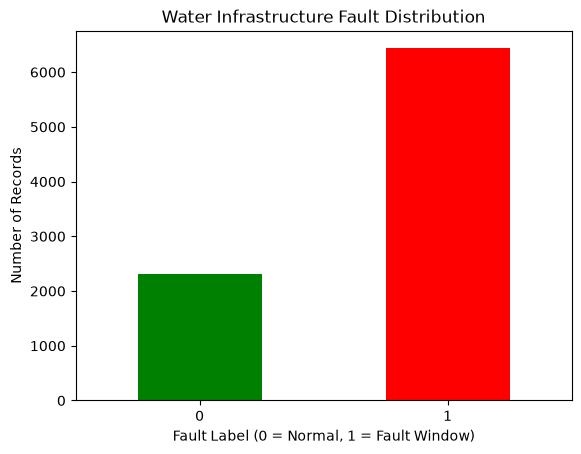

In [5]:
import matplotlib.pyplot as plt

df["fault_d7"].value_counts().sort_index().plot(
    kind="bar",
    color=["green", "red"]
)

plt.title("Water Infrastructure Fault Distribution")
plt.xlabel("Fault Label (0 = Normal, 1 = Fault Window)")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()

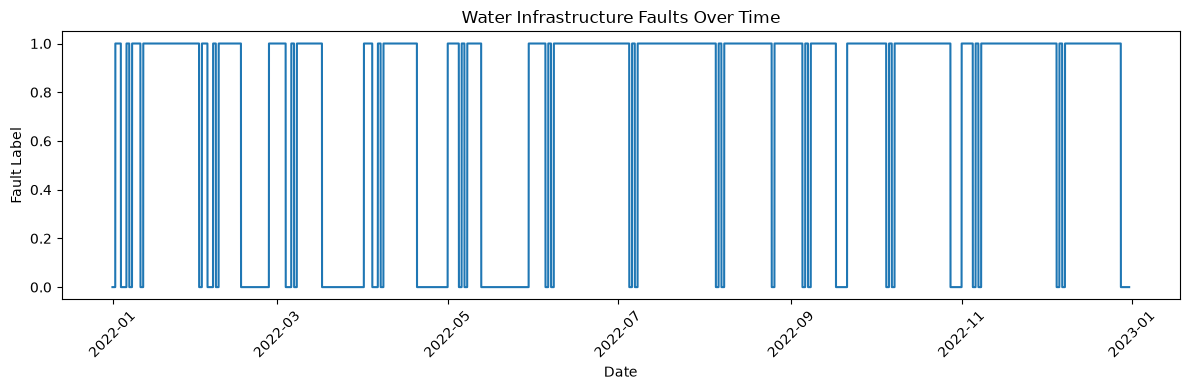

In [6]:
plt.figure(figsize=(12, 4))

plt.plot(df["timestamp"], df["fault_d7"])

plt.title("Water Infrastructure Faults Over Time")
plt.xlabel("Date")
plt.ylabel("Fault Label")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

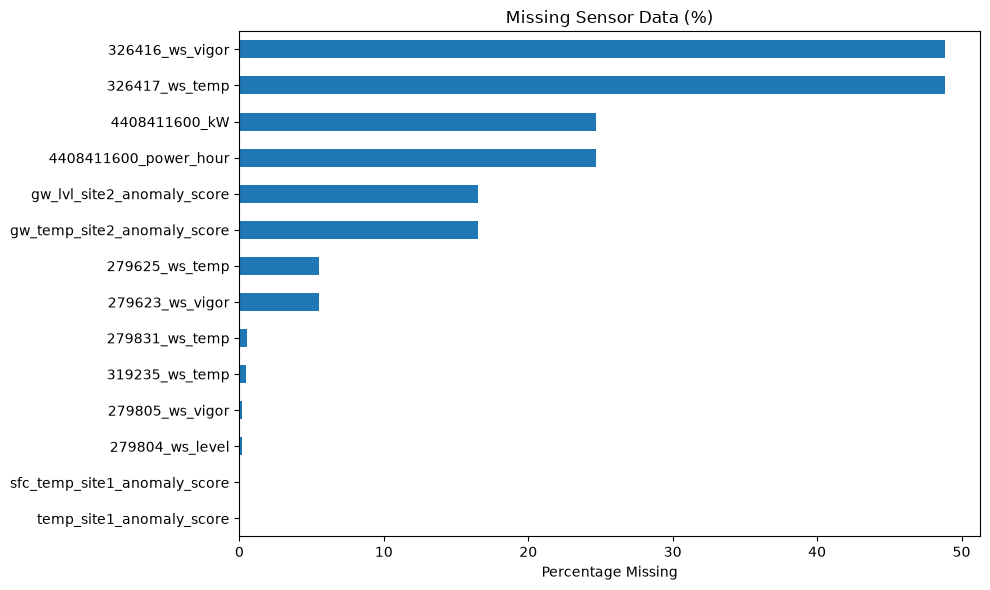

In [7]:
missing = df.isnull().mean() * 100

missing = missing[missing > 0].sort_values()

plt.figure(figsize=(10, 6))
missing.plot(kind="barh")

plt.title("Missing Sensor Data (%)")
plt.xlabel("Percentage Missing")
plt.tight_layout()
plt.show()

In [8]:
df.describe().round(2)


,timestamp,fault_d7,4700008966_kW,4700008966_power_hour,4408411600_kW,4408411600_power_hour,4608927500_kvar_hour,238045_ws_temp,279805_ws_vigor,279804_ws_level,279625_ws_temp,279623_ws_vigor,319235_ws_temp,279831_ws_temp,326417_ws_temp,326416_ws_vigor,temp_site1_anomaly_score,sfc_temp_site1_anomaly_score,gw_lvl_site2_anomaly_score,gw_temp_site2_anomaly_score
count,8737,8737.00,8737.00,8737.00,6578.00,6578.00,8737.00,8737.00,8724.00,8724.00,8256.00,8256.00,8700.00,8694.00,4470.00,4470.00,8736.00,8736.00,7296.00,7296.00
mean,2022-07-01 23:00:00,0.74,1.24,1.23,0.19,0.33,0.50,0.11,0.87,0.37,0.28,0.30,0.40,0.46,0.90,2.56,13.02,13.33,32.17,35.13
min,2021-12-31 23:00:00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2022-04-01 23:00:00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,4.90,4.63,9.48,18.90
50%,2022-07-01 23:00:00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,6.91,6.56,29.35,27.96
75%,2022-09-30 23:00:00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.15,12.83,16.45,50.80,55.03
max,2022-12-30 23:00:00,1.00,99.08,99.08,94.84,97.25,99.01,95.76,91.96,85.69,67.27,67.27,91.63,64.26,52.90,94.25,100.00,100.00,100.00,100.00
std,NaN,0.44,8.65,8.62,3.12,4.29,5.71,2.18,6.22,4.79,3.46,3.58,4.46,3.45,5.47,10.15,15.87,16.02,24.55,24.11


In [9]:
correlations = (
    df.select_dtypes(include="number")
    .corr()["fault_d7"]
    .drop("fault_d7")
    .sort_values()
)

print(correlations.round(3))

4408411600_power_hour          -0.013
4608927500_kvar_hour           -0.007
279625_ws_temp                  0.018
279804_ws_level                 0.018
279623_ws_vigor                 0.019
4408411600_kW                   0.020
238045_ws_temp                  0.020
279831_ws_temp                  0.050
319235_ws_temp                  0.054
326417_ws_temp                  0.065
4700008966_kW                   0.067
4700008966_power_hour           0.068
279805_ws_vigor                 0.079
326416_ws_vigor                 0.084
sfc_temp_site1_anomaly_score    0.126
temp_site1_anomaly_score        0.151
gw_temp_site2_anomaly_score     0.254
gw_lvl_site2_anomaly_score      0.322
Name: fault_d7, dtype: float64


In [10]:
df.to_csv("../data/processed/water_data.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [11]:
split = int(len(df) * 0.8)

train = df.iloc[:split].copy()
test = df.iloc[split:].copy()

print("Training rows:", len(train))
print("Testing rows:", len(test))

print("Training faults:", train["fault_d7"].value_counts())
print("Testing faults:", test["fault_d7"].value_counts())

Training rows: 6989
Testing rows: 1748
Training faults: fault_d7
1    4948
0    2041
Name: count, dtype: int64
Testing faults: fault_d7
1    1484
0     264
Name: count, dtype: int64


In [12]:
X_train = train.drop(columns=["timestamp", "fault_d7"])
X_test = test.drop(columns=["timestamp", "fault_d7"])

y_train = train["fault_d7"]
y_test = test["fault_d7"]

medians = X_train.median()

X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print("Training missing values:", X_train.isnull().sum().sum())
print("Testing missing values:", X_test.isnull().sum().sum())

Training missing values: 0
Testing missing values: 0


In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.81      0.35      0.49       264
           1       0.89      0.99      0.94      1484

    accuracy                           0.89      1748
   macro avg       0.85      0.67      0.71      1748
weighted avg       0.88      0.89      0.87      1748



In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.81      0.35      0.49       264
           1       0.89      0.99      0.94      1484

    accuracy                           0.89      1748
   macro avg       0.85      0.67      0.71      1748
weighted avg       0.88      0.89      0.87      1748



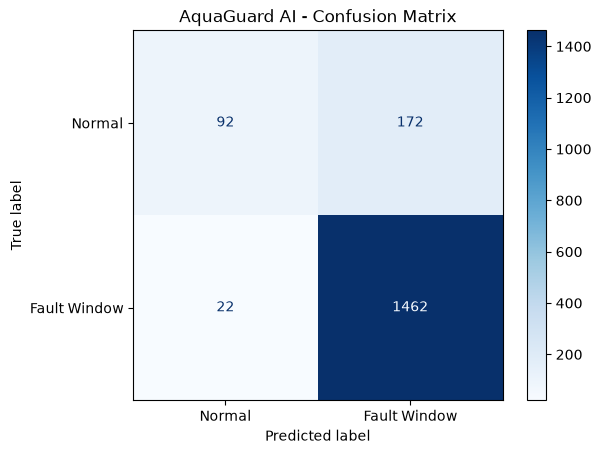

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Normal", "Fault Window"],
    cmap="Blues"
)

plt.title("AquaGuard AI - Confusion Matrix")
plt.show()

In [16]:
from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

print("Correct normal predictions:", tn)
print("False alarms:", fp)
print("Missed fault windows:", fn)
print("Correct fault predictions:", tp)

Correct normal predictions: 92
False alarms: 172
Missed fault windows: 22
Correct fault predictions: 1462


In [17]:
importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance.head(10))

gw_temp_site2_anomaly_score     0.376468
gw_lvl_site2_anomaly_score      0.360291
temp_site1_anomaly_score        0.088509
sfc_temp_site1_anomaly_score    0.068376
326416_ws_vigor                 0.034436
4608927500_kvar_hour            0.014817
4700008966_kW                   0.010710
4700008966_power_hour           0.010704
279805_ws_vigor                 0.005718
279804_ws_level                 0.004816
dtype: float64


In [19]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score
import numpy as np

baseline_pred = np.ones(len(y_test), dtype=int)

print("Baseline accuracy:",
      round(accuracy_score(y_test, baseline_pred), 3))

print("Random Forest accuracy:",
      round(accuracy_score(y_test, y_pred), 3))

print("Random Forest balanced accuracy:",
      round(balanced_accuracy_score(y_test, y_pred), 3))

Baseline accuracy: 0.849
Random Forest accuracy: 0.889
Random Forest balanced accuracy: 0.667


In [20]:
from sklearn.metrics import classification_report

probabilities = model.predict_proba(X_test)[:, 1]

y_pred_07 = (probabilities >= 0.7).astype(int)

print(classification_report(
    y_test,
    y_pred_07,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.63      0.36      0.46       264
           1       0.89      0.96      0.93      1484

    accuracy                           0.87      1748
   macro avg       0.76      0.66      0.69      1748
weighted avg       0.85      0.87      0.86      1748



In [21]:
split_val = int(len(train) * 0.8)

train_new = train.iloc[:split_val].copy()
val = train.iloc[split_val:].copy()

print("Training:", len(train_new))
print("Validation:", len(val))
print("Testing:", len(test))

print("\nValidation labels:")
print(val["fault_d7"].value_counts())

Training: 5591
Validation: 1398
Testing: 1748

Validation labels:
fault_d7
1    1182
0     216
Name: count, dtype: int64


In [22]:
X_train_new = train_new.drop(columns=["timestamp", "fault_d7"])
X_val = val.drop(columns=["timestamp", "fault_d7"])

y_train_new = train_new["fault_d7"]
y_val = val["fault_d7"]

medians_new = X_train_new.median()

X_train_new = X_train_new.fillna(medians_new)
X_val = X_val.fillna(medians_new)

print("Training missing:", X_train_new.isna().sum().sum())
print("Validation missing:", X_val.isna().sum().sum())

Training missing: 0
Validation missing: 0


In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

model_v2 = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_v2.fit(X_train_new, y_train_new)

val_pred = model_v2.predict(X_val)

print(classification_report(
    y_val,
    val_pred,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.54      0.19      0.28       216
           1       0.87      0.97      0.92      1182

    accuracy                           0.85      1398
   macro avg       0.70      0.58      0.60      1398
weighted avg       0.82      0.85      0.82      1398



In [24]:
from sklearn.metrics import precision_score, recall_score, balanced_accuracy_score

val_probs = model_v2.predict_proba(X_val)[:, 1]

for threshold in [0.3, 0.5, 0.7, 0.9]:
    predictions = (val_probs >= threshold).astype(int)

    print(
        f"Threshold: {threshold} | "
        f"Precision: {precision_score(y_val, predictions, zero_division=0):.3f} | "
        f"Recall: {recall_score(y_val, predictions, zero_division=0):.3f} | "
        f"Balanced Accuracy: {balanced_accuracy_score(y_val, predictions):.3f}"
    )

Threshold: 0.3 | Precision: 0.859 | Recall: 0.999 | Balanced Accuracy: 0.551
Threshold: 0.5 | Precision: 0.866 | Recall: 0.972 | Balanced Accuracy: 0.574
Threshold: 0.7 | Precision: 0.877 | Recall: 0.886 | Balanced Accuracy: 0.603
Threshold: 0.9 | Precision: 0.867 | Recall: 0.601 | Balanced Accuracy: 0.548


In [25]:
from sklearn.metrics import confusion_matrix

pred_07 = (val_probs >= 0.7).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_val, pred_07
).ravel()

print("Correct normal:", tn)
print("False alarms:", fp)
print("Missed fault windows:", fn)
print("Correct fault windows:", tp)

Correct normal: 69
False alarms: 147
Missed fault windows: 135
Correct fault windows: 1047


In [26]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, balanced_accuracy_score

log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

log_model.fit(X_train_new, y_train_new)

log_pred = log_model.predict(X_val)

print(classification_report(y_val, log_pred, zero_division=0))

print("Balanced accuracy:",
      round(balanced_accuracy_score(y_val, log_pred), 3))

              precision    recall  f1-score   support

           0       0.54      0.39      0.45       216
           1       0.89      0.94      0.92      1182

    accuracy                           0.85      1398
   macro avg       0.72      0.66      0.68      1398
weighted avg       0.84      0.85      0.84      1398

Balanced accuracy: 0.664


In [27]:
tn, fp, fn, tp = confusion_matrix(
    y_val, log_pred
).ravel()

print("Correct normal:", tn)
print("False alarms:", fp)
print("Missed fault windows:", fn)
print("Correct fault windows:", tp)

Correct normal: 84
False alarms: 132
Missed fault windows: 71
Correct fault windows: 1111


In [28]:
log_probs = log_model.predict_proba(X_val)[:, 1]

for threshold in [0.3, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = (log_probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

    print(
        f"Threshold: {threshold} | "
        f"False alarms: {fp} | "
        f"Missed faults: {fn} | "
        f"Balanced accuracy: "
        f"{balanced_accuracy_score(y_val, pred):.3f}"
    )

Threshold: 0.3 | False alarms: 144 | Missed faults: 0 | Balanced accuracy: 0.667
Threshold: 0.5 | False alarms: 132 | Missed faults: 71 | Balanced accuracy: 0.664
Threshold: 0.6 | False alarms: 126 | Missed faults: 174 | Balanced accuracy: 0.635
Threshold: 0.7 | False alarms: 126 | Missed faults: 251 | Balanced accuracy: 0.602
Threshold: 0.8 | False alarms: 120 | Missed faults: 425 | Balanced accuracy: 0.542
Threshold: 0.9 | False alarms: 31 | Missed faults: 893 | Balanced accuracy: 0.550


In [29]:
df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.dayofweek
df["month"] = df["timestamp"].dt.month

print(df[["hour", "day_of_week", "month"]].head())

   hour  day_of_week  month
0    23            4     12
1     0            5      1
2     1            5      1
3     2            5      1
4     3            5      1


C:\Users\Admin\AppData\Local\Temp\ipykernel_6516\2557587978.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["timestamp"].dt.dayofweek


In [30]:
df["day_of_week"] = df["timestamp"].dt.day_of_week

print(df[["hour", "day_of_week", "month"]].head())

   hour  day_of_week  month
0    23            4     12
1     0            5      1
2     1            5      1
3     2            5      1
4     3            5      1


In [31]:
time_features = ["hour", "day_of_week", "month"]

X_train_time = X_train_new.copy()
X_val_time = X_val.copy()

X_train_time[time_features] = df.loc[
    train_new.index, time_features
]

X_val_time[time_features] = df.loc[
    val.index, time_features
]

print("Training features:", X_train_time.shape[1])
print("Validation features:", X_val_time.shape[1])

Training features: 21
Validation features: 21


In [32]:
log_model_time = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

log_model_time.fit(X_train_time, y_train_new)

time_pred = log_model_time.predict(X_val_time)

print(classification_report(y_val, time_pred, zero_division=0))

print("Balanced accuracy:",
      round(balanced_accuracy_score(y_val, time_pred), 3))

              precision    recall  f1-score   support

           0       1.00      0.32      0.49       216
           1       0.89      1.00      0.94      1182

    accuracy                           0.90      1398
   macro avg       0.95      0.66      0.72      1398
weighted avg       0.91      0.90      0.87      1398

Balanced accuracy: 0.662


In [33]:
print("Training period:")
print(train_new["timestamp"].min())
print(train_new["timestamp"].max())

print("\nValidation period:")
print(val["timestamp"].min())
print(val["timestamp"].max())

print("\nFault labels around the split:")
print(df.loc[split_val-3:split_val+3,
             ["timestamp", "fault_d7"]])

Training period:
2021-12-31 23:00:00
2022-08-21 21:00:00

Validation period:
2022-08-21 22:00:00
2022-10-19 03:00:00

Fault labels around the split:
               timestamp  fault_d7
5588 2022-08-21 19:00:00         1
5589 2022-08-21 20:00:00         1
5590 2022-08-21 21:00:00         1
5591 2022-08-21 22:00:00         1
5592 2022-08-21 23:00:00         1
5593 2022-08-22 00:00:00         1
5594 2022-08-22 01:00:00         1


In [34]:
gap = 7 * 24  # 7 days in hours

train_safe = train_new.iloc[:-gap].copy()
val_safe = val.iloc[gap:].copy()

print("Training rows:", len(train_safe))
print("Validation rows:", len(val_safe))

print("\nTraining ends:", train_safe["timestamp"].max())
print("Validation starts:", val_safe["timestamp"].min())

print("\nValidation labels:")
print(val_safe["fault_d7"].value_counts())

Training rows: 5423
Validation rows: 1230

Training ends: 2022-08-14 21:00:00
Validation starts: 2022-08-28 22:00:00

Validation labels:
fault_d7
1    1038
0     192
Name: count, dtype: int64


In [35]:
features = X_train_new.columns.tolist()

X_train_safe = train_safe[features].copy()
X_val_safe = val_safe[features].copy()

y_train_safe = train_safe["fault_d7"]
y_val_safe = val_safe["fault_d7"]

medians_safe = X_train_safe.median()

X_train_safe = X_train_safe.fillna(medians_safe)
X_val_safe = X_val_safe.fillna(medians_safe)

print("Training missing:", X_train_safe.isna().sum().sum())
print("Validation missing:", X_val_safe.isna().sum().sum())

Training missing: 0
Validation missing: 0


In [36]:
log_model_safe = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

log_model_safe.fit(X_train_safe, y_train_safe)

safe_pred = log_model_safe.predict(X_val_safe)

print(classification_report(
    y_val_safe, safe_pred, zero_division=0
))

print("Balanced accuracy:",
      round(balanced_accuracy_score(y_val_safe, safe_pred), 3))

              precision    recall  f1-score   support

           0       0.59      0.44      0.50       192
           1       0.90      0.94      0.92      1038

    accuracy                           0.87      1230
   macro avg       0.75      0.69      0.71      1230
weighted avg       0.85      0.87      0.86      1230

Balanced accuracy: 0.691


In [37]:
tn, fp, fn, tp = confusion_matrix(
    y_val_safe, safe_pred
).ravel()

print("Correct normal:", tn)
print("False alarms:", fp)
print("Missed fault windows:", fn)
print("Correct fault windows:", tp)

Correct normal: 84
False alarms: 108
Missed fault windows: 58
Correct fault windows: 980


In [38]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, balanced_accuracy_score

boost_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    random_state=42
)

boost_model.fit(X_train_safe, y_train_safe)

boost_pred = boost_model.predict(X_val_safe)

print(classification_report(
    y_val_safe, boost_pred, zero_division=0
))

print("Balanced accuracy:",
      round(balanced_accuracy_score(y_val_safe, boost_pred), 3))

              precision    recall  f1-score   support

           0       0.53      0.25      0.34       192
           1       0.87      0.96      0.91      1038

    accuracy                           0.85      1230
   macro avg       0.70      0.60      0.63      1230
weighted avg       0.82      0.85      0.82      1230

Balanced accuracy: 0.605


In [40]:
safe_probs = log_model_safe.predict_proba(X_val_safe)[:, 1]

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pred = (safe_probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_safe, pred
    ).ravel()

    print(
        f"Threshold: {threshold} | "
        f"False alarms: {fp} | "
        f"Missed faults: {fn} | "
        f"Balanced accuracy: "
        f"{balanced_accuracy_score(y_val_safe, pred):.3f}"
    )

Threshold: 0.3 | False alarms: 126 | Missed faults: 0 | Balanced accuracy: 0.672
Threshold: 0.4 | False alarms: 112 | Missed faults: 20 | Balanced accuracy: 0.699
Threshold: 0.5 | False alarms: 108 | Missed faults: 58 | Balanced accuracy: 0.691
Threshold: 0.6 | False alarms: 104 | Missed faults: 150 | Balanced accuracy: 0.657
Threshold: 0.7 | False alarms: 102 | Missed faults: 249 | Balanced accuracy: 0.614
Threshold: 0.8 | False alarms: 102 | Missed faults: 375 | Balanced accuracy: 0.554


In [41]:
import joblib

joblib.dump(
    {
        "model": log_model_safe,
        "medians": medians_safe,
        "features": features,
        "threshold": 0.4
    },
    "../models/aquaguard_v1.joblib"
)

print("AquaGuard AI model saved successfully!")

AquaGuard AI model saved successfully!


In [42]:
print("Validation ends:", val_safe["timestamp"].max())
print("Test begins:", test["timestamp"].min())

print("Gap:", test["timestamp"].min() -
      val_safe["timestamp"].max())

Validation ends: 2022-10-19 03:00:00
Test begins: 2022-10-19 04:00:00
Gap: 0 days 01:00:00


In [43]:
gap = 7 * 24

test_safe = test.iloc[gap:].copy()

print("New test starts:", test_safe["timestamp"].min())
print("Test observations:", len(test_safe))
print("Gap:", test_safe["timestamp"].min() -
      val_safe["timestamp"].max())

New test starts: 2022-10-26 04:00:00
Test observations: 1580
Gap: 7 days 01:00:00


In [44]:
X_test_safe = test_safe[features].fillna(medians_safe)
y_test_safe = test_safe["fault_d7"]

test_probs = log_model_safe.predict_proba(X_test_safe)[:, 1]
test_pred = (test_probs >= 0.4).astype(int)

print(classification_report(y_test_safe, test_pred, zero_division=0))

print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test_safe, test_pred), 3))

print("Confusion matrix:")
print(confusion_matrix(y_test_safe, test_pred))

              precision    recall  f1-score   support

           0       0.28      0.29      0.29       264
           1       0.86      0.85      0.85      1316

    accuracy                           0.76      1580
   macro avg       0.57      0.57      0.57      1580
weighted avg       0.76      0.76      0.76      1580

Balanced accuracy: 0.57
Confusion matrix:
[[  77  187]
 [ 199 1117]]


In [45]:
print("Training:")
print(y_train_safe.value_counts(normalize=True).round(3))

print("\nValidation:")
print(y_val_safe.value_counts(normalize=True).round(3))

print("\nTest:")
print(y_test_safe.value_counts(normalize=True).round(3))

Training:
fault_d7
1    0.663
0    0.337
Name: proportion, dtype: float64

Validation:
fault_d7
1    0.844
0    0.156
Name: proportion, dtype: float64

Test:
fault_d7
1    0.833
0    0.167
Name: proportion, dtype: float64


In [47]:
comparison = pd.DataFrame({
    "Training": X_train_safe.mean(),
    "Validation": X_val_safe.mean(),
    "Test": X_test_safe.mean()
})

print(comparison.round(2))

                              Training  Validation   Test
4700008966_kW                     1.30        2.37   0.17
4700008966_power_hour             1.29        2.37   0.17
4408411600_kW                     0.16        0.15   0.07
4408411600_power_hour             0.19        0.71   0.14
4608927500_kvar_hour              0.66        0.09   0.13
238045_ws_temp                    0.10        0.19   0.09
279805_ws_vigor                   0.32        3.04   1.26
279804_ws_level                   0.08        2.24   0.02
279625_ws_temp                    0.09        1.13   0.28
279623_ws_vigor                   0.13        1.25   0.12
319235_ws_temp                    0.50        0.52   0.09
279831_ws_temp                    0.38        0.14   1.12
326417_ws_temp                    0.42        0.41   0.61
326416_ws_vigor                   0.87        0.92   3.55
temp_site1_anomaly_score         13.56        8.93  12.57
sfc_temp_site1_anomaly_score     14.05        8.92  13.24
gw_lvl_site2_a

In [48]:
missing_comparison = pd.DataFrame({
    "Training": train_safe[features].isna().mean() * 100,
    "Validation": val_safe[features].isna().mean() * 100,
    "Test": test_safe[features].isna().mean() * 100
})

print(missing_comparison.round(1))

                              Training  Validation  Test
4700008966_kW                      0.0         0.0   0.0
4700008966_power_hour              0.0         0.0   0.0
4408411600_kW                     34.5        11.7   9.1
4408411600_power_hour             34.5        11.7   9.1
4608927500_kvar_hour               0.0         0.0   0.0
238045_ws_temp                     0.0         0.0   0.0
279805_ws_vigor                    0.2         0.0   0.0
279804_ws_level                    0.2         0.0   0.0
279625_ws_temp                     7.1         3.9   3.0
279623_ws_vigor                    7.1         3.9   3.0
319235_ws_temp                     0.7         0.0   0.0
279831_ws_temp                     0.8         0.0   0.0
326417_ws_temp                    68.1        23.4  18.2
326416_ws_vigor                   68.1        23.4  18.2
temp_site1_anomaly_score           0.0         0.0   0.0
sfc_temp_site1_anomaly_score       0.0         0.0   0.0
gw_lvl_site2_anomaly_score     

In [49]:
groundwater_available = test_safe[
    "gw_lvl_site2_anomaly_score"
].notna()

for name, mask in [
    ("Groundwater available", groundwater_available),
    ("Groundwater missing", ~groundwater_available)
]:
    print("\n", name)
    print("Observations:", mask.sum())
    print("Balanced accuracy:",
          round(balanced_accuracy_score(
              y_test_safe[mask],
              test_pred[mask]
          ), 3))


 Groundwater available
Observations: 620
Balanced accuracy: 0.687

 Groundwater missing
Observations: 960
Balanced accuracy: 0.395


In [50]:
print(pd.crosstab(
    test_safe["gw_lvl_site2_anomaly_score"].isna(),
    test_safe["fault_d7"],
    normalize="index"
).round(3))

fault_d7                        0      1
gw_lvl_site2_anomaly_score              
False                       0.310  0.690
True                        0.075  0.925


In [51]:
print(pd.crosstab(
    train_safe["gw_lvl_site2_anomaly_score"].isna(),
    train_safe["fault_d7"],
    normalize="index"
).round(3))

fault_d7                        0      1
gw_lvl_site2_anomaly_score              
False                       0.357  0.643
True                        0.065  0.935


In [52]:
train_improved = train_safe.copy()
val_improved = val_safe.copy()

for dataset in [train_improved, val_improved]:
    dataset["gw_missing"] = (
        dataset["gw_lvl_site2_anomaly_score"]
        .isna()
        .astype(int)
    )

print(train_improved["gw_missing"].value_counts())
print(val_improved["gw_missing"].value_counts())

gw_missing
0    5038
1     385
Name: count, dtype: int64
gw_missing
0    1134
1      96
Name: count, dtype: int64


In [53]:
features_v2 = features + ["gw_missing"]

X_train_v2 = train_improved[features_v2]
X_val_v2 = val_improved[features_v2]

medians_v2 = X_train_v2.median()

X_train_v2 = X_train_v2.fillna(medians_v2)
X_val_v2 = X_val_v2.fillna(medians_v2)

log_model_v2 = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

log_model_v2.fit(X_train_v2, y_train_safe)

pred_v2 = (
    log_model_v2.predict_proba(X_val_v2)[:, 1] >= 0.4
).astype(int)

print(classification_report(y_val_safe, pred_v2))
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_val_safe, pred_v2), 3))

              precision    recall  f1-score   support

           0       0.76      0.42      0.54       192
           1       0.90      0.98      0.94      1038

    accuracy                           0.89      1230
   macro avg       0.83      0.70      0.74      1230
weighted avg       0.88      0.89      0.88      1230

Balanced accuracy: 0.699


In [54]:
print("AquaGuard v1:")
print(confusion_matrix(y_val_safe, (safe_probs >= 0.4).astype(int)))

print("\nAquaGuard v2:")
print(confusion_matrix(y_val_safe, pred_v2))

AquaGuard v1:
[[  80  112]
 [  20 1018]]

AquaGuard v2:
[[  81  111]
 [  25 1013]]


In [55]:
v2_probs = log_model_v2.predict_proba(X_val_v2)[:, 1]

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (v2_probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_safe, pred
    ).ravel()

    print(
        f"{threshold}: "
        f"False alarms={fp}, "
        f"Missed faults={fn}, "
        f"Balanced accuracy="
        f"{balanced_accuracy_score(y_val_safe, pred):.3f}"
    )

0.3: False alarms=117, Missed faults=0, Balanced accuracy=0.695
0.4: False alarms=111, Missed faults=25, Balanced accuracy=0.699
0.5: False alarms=108, Missed faults=56, Balanced accuracy=0.692
0.6: False alarms=102, Missed faults=145, Balanced accuracy=0.665
0.7: False alarms=102, Missed faults=252, Balanced accuracy=0.613


In [56]:
importance = pd.DataFrame({
    "Feature": features,
    "Coefficient": log_model_safe.named_steps[
        "logisticregression"
    ].coef_[0]
})

importance["Absolute"] = importance["Coefficient"].abs()

print(
    importance.sort_values(
        "Absolute", ascending=False
    ).head(10)
)


                        Feature  Coefficient  Absolute
13              326416_ws_vigor     5.241692  5.241692
7               279804_ws_level     1.713308  1.713308
12               326417_ws_temp     1.210077  1.210077
16   gw_lvl_site2_anomaly_score     0.923860  0.923860
1         4700008966_power_hour     0.787694  0.787694
10               319235_ws_temp     0.695189  0.695189
0                 4700008966_kW    -0.668278  0.668278
17  gw_temp_site2_anomaly_score     0.524869  0.524869
14     temp_site1_anomaly_score     0.339171  0.339171
8                279625_ws_temp    -0.295345  0.295345


In [57]:
cols = [
    "326416_ws_vigor",
    "326417_ws_temp",
    "279804_ws_level",
    "gw_lvl_site2_anomaly_score",
    "fault_d7"
]

print(train_safe[cols].corr().round(2))

                            326416_ws_vigor  326417_ws_temp  279804_ws_level  \
326416_ws_vigor                        1.00           -0.04            -0.01   
326417_ws_temp                        -0.04            1.00            -0.01   
279804_ws_level                       -0.01           -0.01             1.00   
gw_lvl_site2_anomaly_score             0.05            0.11            -0.03   
fault_d7                               0.09            0.07             0.03   

                            gw_lvl_site2_anomaly_score  fault_d7  
326416_ws_vigor                                   0.05      0.09  
326417_ws_temp                                    0.11      0.07  
279804_ws_level                                  -0.03      0.03  
gw_lvl_site2_anomaly_score                        1.00      0.38  
fault_d7                                          0.38      1.00  


In [58]:
print(
    train_safe["326416_ws_vigor"]
    .describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])
)

count    1732.000000
mean        2.719197
std        10.730137
min         0.000000
1%          0.000000
25%         0.000000
50%         0.000000
75%         0.000000
99%        56.126995
max        89.774930
Name: 326416_ws_vigor, dtype: float64


In [59]:
sensor = train_safe["326416_ws_vigor"]

print("Missing:", sensor.isna().sum())
print("Zeros:", (sensor == 0).sum())
print("Positive readings:", (sensor > 0).sum())


Missing: 3691
Zeros: 1330
Positive readings: 402


In [60]:
sensor_status = pd.Series(
    np.where(
        train_safe["326416_ws_vigor"].isna(),
        "Missing",
        np.where(
            train_safe["326416_ws_vigor"] == 0,
            "Zero",
            "Positive"
        )
    ),
    index=train_safe.index
)

print(pd.crosstab(
    sensor_status,
    train_safe["fault_d7"],
    normalize="index"
).round(3))

fault_d7      0      1
row_0                 
Missing   0.436  0.564
Positive  0.060  0.940
Zero      0.144  0.856


In [61]:
train_v3 = train_improved.copy()
val_v3 = val_improved.copy()

for dataset in [train_v3, val_v3]:
    dataset["vigor_missing"] = (
        dataset["326416_ws_vigor"].isna().astype(int)
    )

features_v3 = features_v2 + ["vigor_missing"]

print(train_v3["vigor_missing"].value_counts())
print(val_v3["vigor_missing"].value_counts())

vigor_missing
1    3691
0    1732
Name: count, dtype: int64
vigor_missing
0    942
1    288
Name: count, dtype: int64


In [62]:
X_train_v3 = train_v3[features_v3]
X_val_v3 = val_v3[features_v3]

medians_v3 = X_train_v3.median()

X_train_v3 = X_train_v3.fillna(medians_v3)
X_val_v3 = X_val_v3.fillna(medians_v3)

log_model_v3 = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

log_model_v3.fit(X_train_v3, y_train_safe)

pred_v3 = (
    log_model_v3.predict_proba(X_val_v3)[:, 1] >= 0.4
).astype(int)

print(classification_report(y_val_safe, pred_v3))
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_val_safe, pred_v3), 3))

              precision    recall  f1-score   support

           0       0.74      0.42      0.54       192
           1       0.90      0.97      0.94      1038

    accuracy                           0.89      1230
   macro avg       0.82      0.70      0.74      1230
weighted avg       0.88      0.89      0.87      1230

Balanced accuracy: 0.697


In [63]:
print("AquaGuard v3 confusion matrix:")
print(confusion_matrix(y_val_safe, pred_v3))

AquaGuard v3 confusion matrix:
[[  81  111]
 [  29 1009]]


In [64]:
rf_v4 = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_v4.fit(X_train_v3, y_train_safe)

rf_pred_v4 = rf_v4.predict(X_val_v3)

print(classification_report(
    y_val_safe, rf_pred_v4, zero_division=0
))

print("Balanced accuracy:",
      round(balanced_accuracy_score(y_val_safe, rf_pred_v4), 3))

              precision    recall  f1-score   support

           0       0.76      0.48      0.59       192
           1       0.91      0.97      0.94      1038

    accuracy                           0.90      1230
   macro avg       0.84      0.73      0.76      1230
weighted avg       0.89      0.90      0.88      1230

Balanced accuracy: 0.726


In [65]:
print(confusion_matrix(y_val_safe, rf_pred_v4))

[[  92  100]
 [  29 1009]]


In [66]:
rf_probs_v4 = rf_v4.predict_proba(X_val_v3)[:, 1]

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (rf_probs_v4 >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_safe, pred
    ).ravel()

    print(
        f"{threshold}: "
        f"False alarms={fp}, "
        f"Missed faults={fn}, "
        f"Balanced accuracy="
        f"{balanced_accuracy_score(y_val_safe, pred):.3f}"
    )

0.3: False alarms=171, Missed faults=6, Balanced accuracy=0.552
0.4: False alarms=122, Missed faults=23, Balanced accuracy=0.671
0.5: False alarms=100, Missed faults=29, Balanced accuracy=0.726
0.6: False alarms=96, Missed faults=96, Balanced accuracy=0.704
0.7: False alarms=96, Missed faults=153, Balanced accuracy=0.676


In [ ]:
cols = [
    "326416_ws_vigor",
    "326417_ws_temp",
    "279804_ws_level",
    "gw_lvl_site2_anomaly_score",
    "fault_d7"
]

print(train_safe[cols].corr().round(2))

                            326416_ws_vigor  326417_ws_temp  279804_ws_level  \
326416_ws_vigor                        1.00           -0.04            -0.01   
326417_ws_temp                        -0.04            1.00            -0.01   
279804_ws_level                       -0.01           -0.01             1.00   
gw_lvl_site2_anomaly_score             0.05            0.11            -0.03   
fault_d7                               0.09            0.07             0.03   

                            gw_lvl_site2_anomaly_score  fault_d7  
326416_ws_vigor                                   0.05      0.09  
326417_ws_temp                                    0.11      0.07  
279804_ws_level                                  -0.03      0.03  
gw_lvl_site2_anomaly_score                        1.00      0.38  
fault_d7                                          0.38      1.00  


In [67]:
import joblib

joblib.dump(
    {
        "model": rf_v4,
        "medians": medians_v3,
        "features": features_v3,
        "threshold": 0.5
    },
    "../models/aquaguard_v4.joblib"
)

print("AquaGuard AI v4 saved successfully!")

AquaGuard AI v4 saved successfully!


In [68]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression v1", "Random Forest v4"],
    "Balanced Accuracy": [0.699, 0.726],
    "False Alarms": [112, 100],
    "Missed Fault Windows": [20, 29]
})

comparison.to_csv("../reports/model_comparison.csv", index=False)

print(comparison)

                    Model  Balanced Accuracy  False Alarms  \
0  Logistic Regression v1              0.699           112   
1        Random Forest v4              0.726           100   

   Missed Fault Windows  
0                    20  
1                    29  
